## Assignment no 10

# SUPPORT VECTOR MACHINE (SVM)



# Drug Response Classification


Step 1: Import librarie

In [6]:

# STEP 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


Step 2: Load the dataset

In [10]:

import pandas as pd

# Load the CSV and automatically detect the delimiter
df = pd.read_csv("Pharma_Industry.csv", sep=None, engine="python")

# Clean column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (500, 6)

Column names:
['Drug Dosage (mg)', 'Systolic Blood Pressure (mmHg)', 'Heart Rate (BPM)', 'Liver Toxicity Index (U/L)', 'Blood Glucose Level (mg/dL)', 'Drug Response']


,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


In [11]:

import pandas as pd

# Read the file and detect common delimiters
df = pd.read_csv("Pharma_Industry.csv", sep=",")

if df.shape[1] == 1:
    df = pd.read_csv("Pharma_Industry.csv", sep=";")

if df.shape[1] == 1:
    df = pd.read_csv("Pharma_Industry.csv", sep="\t")

df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
display(df.head())

assert df.shape[1] == 6, (
    "Expected 6 columns. Please check the file delimiter."
)


Dataset shape: (500, 6)


,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
0,-0.128538,0.303280,-1.881849,0.258286,-0.792011,1
1,-1.846188,2.865142,-0.929511,2.866786,-0.719447,1
2,-1.252393,-1.541613,0.363632,-0.325370,0.191314,0
3,1.992515,-1.142779,-0.766657,0.975286,-0.823355,1
4,0.377100,0.538410,-0.029263,1.896015,-0.960130,1


In [12]:
print(df.info())
print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Class Counts:")
print(df["Drug Response"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB
None

Statistical Summary:


,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000
mean,-0.037761,0.214957,0.062871,0.054398,-0.171863,0.5200
std,0.979891,1.247567,0.971978,0.986001,0.983765,0.5001
min,-3.019512,-3.773897,-2.940389,-3.401277,-3.110431,0.0000
25%,-0.642003,-0.565168,-0.648157,-0.586085,-0.797715,0.0000
50%,-0.019340,0.201532,0.027732,-0.065661,-0.108106,1.0000
75%,0.641151,0.951375,0.710774,0.633914,0.513555,1.0000
max,2.949094,4.111751,3.193108,3.373269,2.518023,1.0000



Missing Values:
Drug Dosage (mg)                  0
Systolic Blood Pressure (mmHg)    0
Heart Rate (BPM)                  0
Liver Toxicity Index (U/L)        0
Blood Glucose Level (mg/dL)       0
Drug Response                     0
dtype: int64

Duplicate Rows: 0

Target Class Counts:
Drug Response
1    260
0    240
Name: count, dtype: int64


Step 3: Data exploration (EDA)

In [13]:

# STEP 3: Explore Dataset

print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nTarget Class Counts:")
print(df["Drug Response"].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Drug Dosage (mg)                500 non-null    float64
 1   Systolic Blood Pressure (mmHg)  500 non-null    float64
 2   Heart Rate (BPM)                500 non-null    float64
 3   Liver Toxicity Index (U/L)      500 non-null    float64
 4   Blood Glucose Level (mg/dL)     500 non-null    float64
 5   Drug Response                   500 non-null    int64  
dtypes: float64(5), int64(1)
memory usage: 23.6 KB

Statistical Summary:


,Drug Dosage (mg),Systolic Blood Pressure (mmHg),Heart Rate (BPM),Liver Toxicity Index (U/L),Blood Glucose Level (mg/dL),Drug Response
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.0000
mean,-0.037761,0.214957,0.062871,0.054398,-0.171863,0.5200
std,0.979891,1.247567,0.971978,0.986001,0.983765,0.5001
min,-3.019512,-3.773897,-2.940389,-3.401277,-3.110431,0.0000
25%,-0.642003,-0.565168,-0.648157,-0.586085,-0.797715,0.0000
50%,-0.019340,0.201532,0.027732,-0.065661,-0.108106,1.0000
75%,0.641151,0.951375,0.710774,0.633914,0.513555,1.0000
max,2.949094,4.111751,3.193108,3.373269,2.518023,1.0000



Missing Values:
Drug Dosage (mg)                  0
Systolic Blood Pressure (mmHg)    0
Heart Rate (BPM)                  0
Liver Toxicity Index (U/L)        0
Blood Glucose Level (mg/dL)       0
Drug Response                     0
dtype: int64

Duplicate Rows: 0

Target Class Counts:
Drug Response
1    260
0    240
Name: count, dtype: int64


Step 4: Handle missing values

In [14]:

# STEP 4: Data Cleaning

# Convert all columns to numeric if needed
df = df.apply(pd.to_numeric, errors="coerce")

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing feature values with their median
feature_cols = [
    "Drug Dosage (mg)",
    "Systolic Blood Pressure (mmHg)",
    "Heart Rate (BPM)",
    "Liver Toxicity Index (U/L)",
    "Blood Glucose Level (mg/dL)"
]

df[feature_cols] = df[feature_cols].fillna(
    df[feature_cols].median()
)

# Remove rows where target is missing
df = df.dropna(subset=["Drug Response"])

# Check target labels
df = df[df["Drug Response"].isin([0, 1])]
df["Drug Response"] = df["Drug Response"].astype(int)

print("Cleaned dataset shape:", df.shape)
print("Missing values remaining:")
print(df.isnull().sum())


Cleaned dataset shape: (500, 6)
Missing values remaining:
Drug Dosage (mg)                  0
Systolic Blood Pressure (mmHg)    0
Heart Rate (BPM)                  0
Liver Toxicity Index (U/L)        0
Blood Glucose Level (mg/dL)       0
Drug Response                     0
dtype: int64


Step 5: Visualize feature distributions

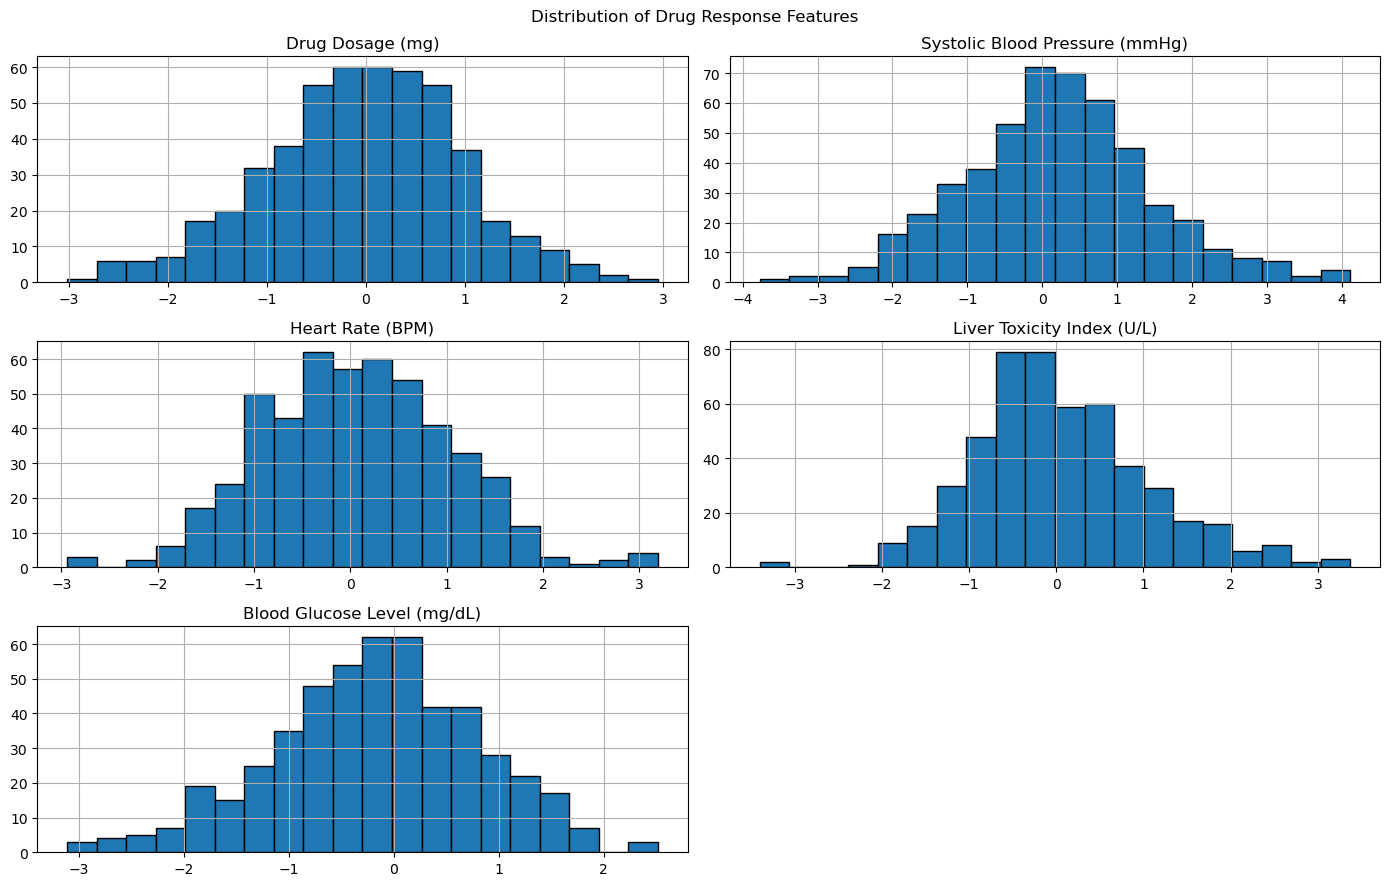

In [15]:

# STEP 5: Histograms

df[feature_cols].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Drug Response Features")
plt.tight_layout()
plt.show()


Step 6: Box plots

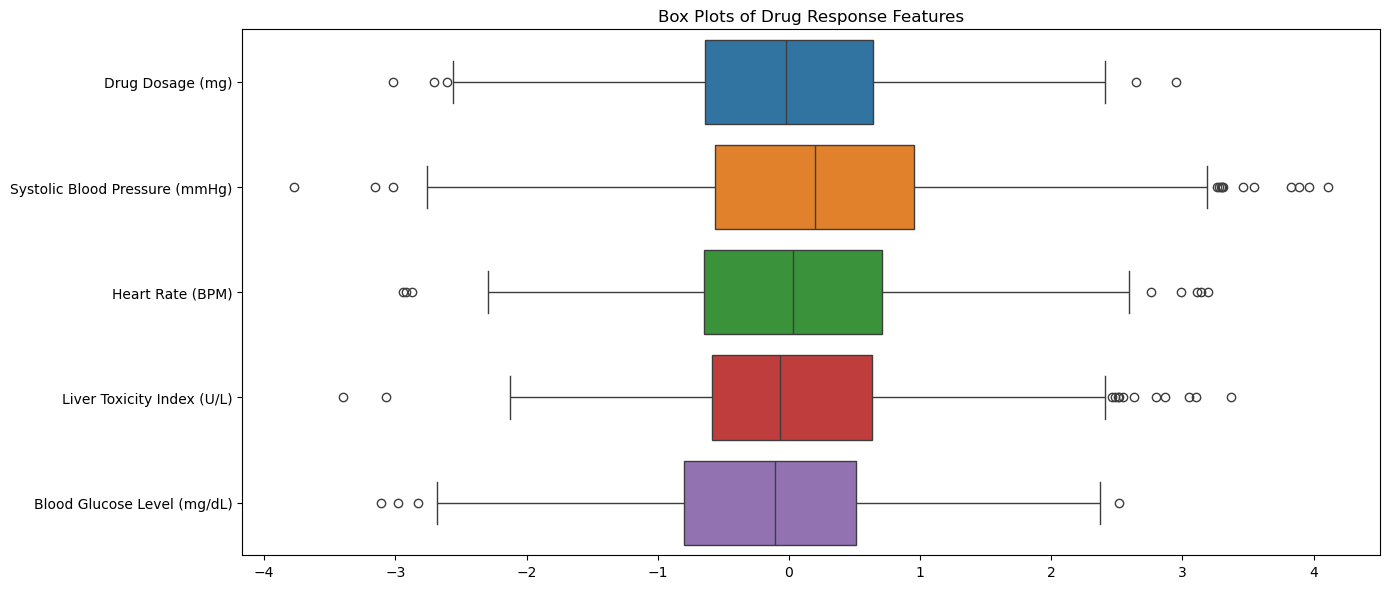

In [16]:

# STEP 6: Detect Potential Outliers

plt.figure(figsize=(14, 6))

sns.boxplot(data=df[feature_cols], orient="h")

plt.title("Box Plots of Drug Response Features")
plt.tight_layout()
plt.show()


Step 7: Correlation heatmap

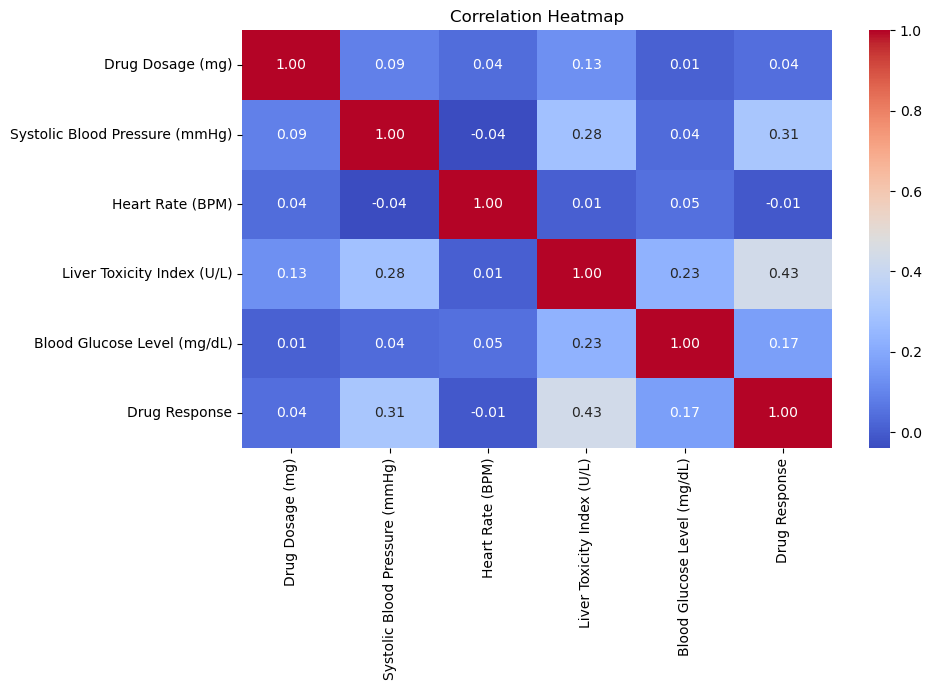

In [17]:

# STEP 7: Feature Correlation

plt.figure(figsize=(10, 7))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


Step 8: Visualize class distribution

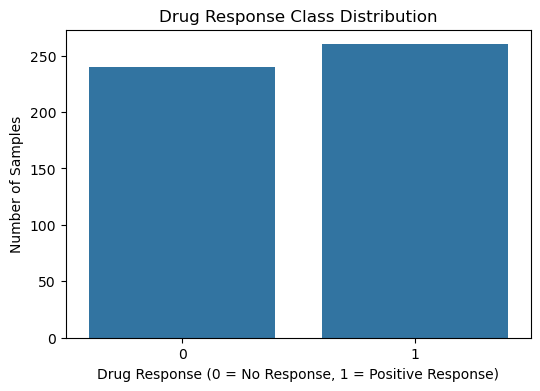

Drug Response
1    260
0    240
Name: count, dtype: int64


In [19]:

# STEP 8: Class Distribution

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Drug Response")

plt.title("Drug Response Class Distribution")
plt.xlabel("Drug Response (0 = No Response, 1 = Positive Response)")
plt.ylabel("Number of Samples")

plt.show()

print(df["Drug Response"].value_counts())


Step 9: Scatter plot and pair plot

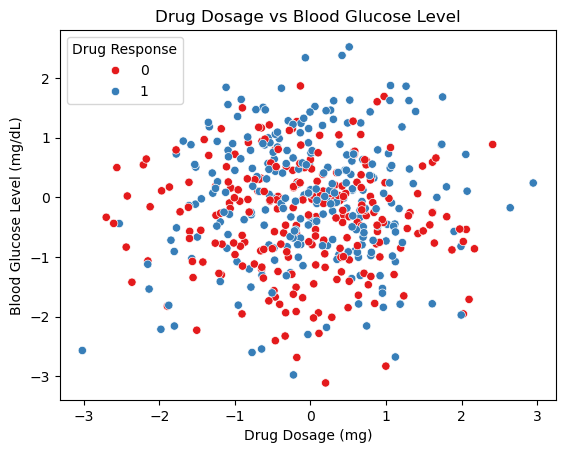

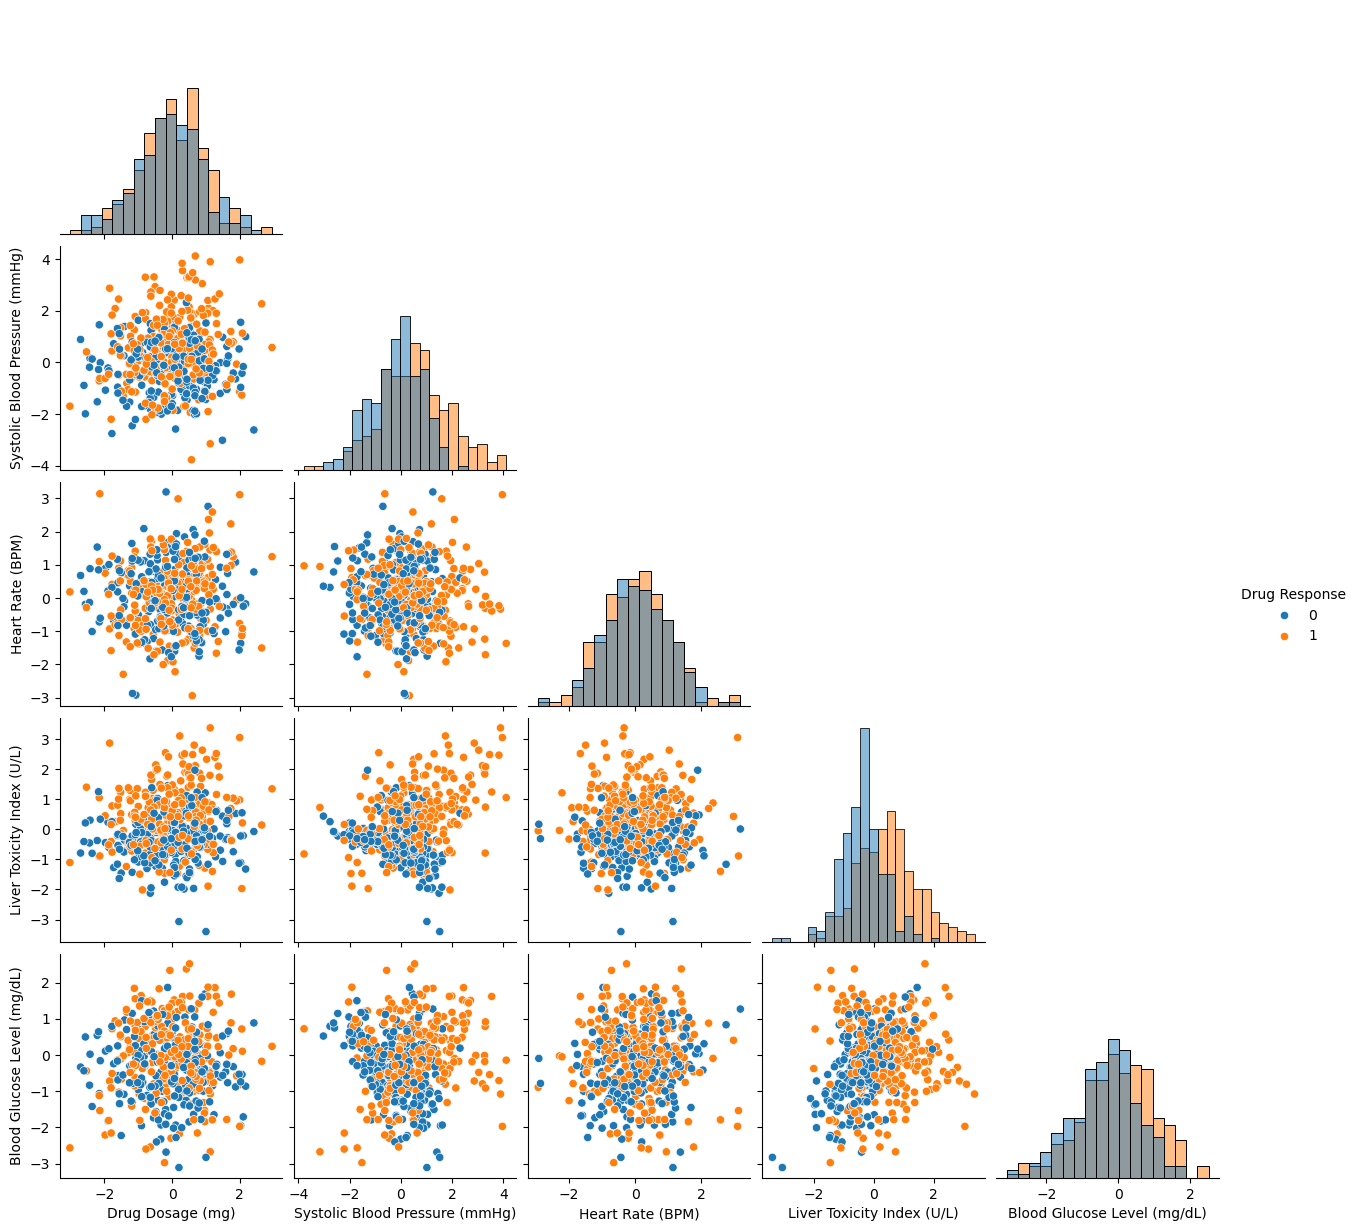

In [20]:

# STEP 9: Data Visualization

sns.scatterplot(
    data=df,
    x="Drug Dosage (mg)",
    y="Blood Glucose Level (mg/dL)",
    hue="Drug Response",
    palette="Set1"
)

plt.title("Drug Dosage vs Blood Glucose Level")
plt.show()

sns.pairplot(
    df,
    vars=feature_cols,
    hue="Drug Response",
    corner=True,
    diag_kind="hist"
)

plt.show()


Step 10: Split the data into training and testing sets

In [21]:

# STEP 10: Separate Features and Target

X = df[feature_cols]
y = df["Drug Response"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])


Training samples: 400
Testing samples: 100
Number of features: 5


Step 11: Train the basic SVM model

In [22]:

# STEP 11: Train SVM Classifier

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0))
])

svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

y_pred = svm_model.predict(X_test)

print("Predictions:")
print(y_pred)


SVM model trained successfully!
Predictions:
[1 1 1 0 0 1 1 0 1 1 1 0 0 1 1 1 0 0 0 0 0 0 1 1 0 1 0 0 1 1 1 1 1 0 0 1 1
 0 0 1 1 0 0 1 0 0 1 0 0 1 0 0 0 1 0 0 0 1 1 1 0 0 0 0 1 0 0 1 1 1 1 1 1 0
 1 1 1 1 0 1 0 1 0 1 1 1 1 1 1 0 0 1 0 1 1 1 1 1 1 1]


Step 12: Evaluate model performance

In [23]:

# STEP 12: Performance Metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Accuracy:  0.7700
Precision: 0.7544
Recall:    0.8269
F1-score:  0.7890

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.71      0.75        48
           1       0.75      0.83      0.79        52

    accuracy                           0.77       100
   macro avg       0.77      0.77      0.77       100
weighted avg       0.77      0.77      0.77       100



Step 13: Confusion matrix

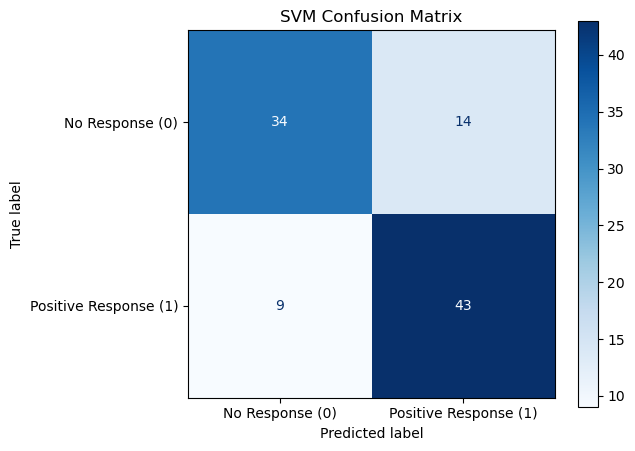

In [24]:

# STEP 13: Visualize Classification Results

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Response (0)", "Positive Response (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()


Step 14: Compare Linear, Polynomial and RBF kernel

In [25]:

# STEP 14: Compare SVM Kernels

kernels = ["linear", "poly", "rbf"]
results = []

for kernel in kernels:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel=kernel, C=1.0))
    ])

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

print("Kernel Comparison:")
display(results_df.round(4))


Kernel Comparison:


,Kernel,Accuracy,Precision,Recall,F1-score
0,linear,0.72,0.7609,0.6731,0.7143
1,poly,0.65,0.6667,0.6538,0.6602
2,rbf,0.77,0.7544,0.8269,0.7890


Step 15: Parameter tuning using GridSearchCV

In [26]:

# STEP 15: Hyperparameter Tuning

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC())
])

param_grid = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__degree": [2, 3],
        "svm__gamma": ["scale"]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.1, 1]
    }
]

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(grid_search.best_score_, 4))


Best Parameters:
{'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'rbf'}

Best Cross-Validation F1-score:
0.7697


Step 16: Evaluate the optimized model

Optimized Model Results
-----------------------
Accuracy: 0.72
Precision: 0.7143
Recall: 0.7692
F1-score: 0.7407


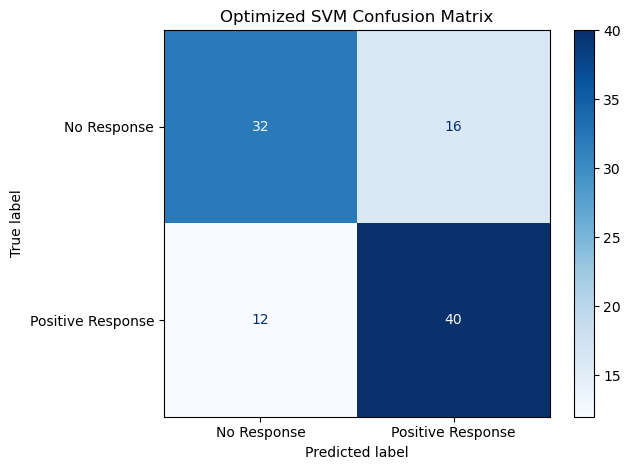

In [27]:

# STEP 16: Best Model Evaluation

best_model = grid_search.best_estimator_

best_pred = best_model.predict(X_test)

print("Optimized Model Results")
print("-----------------------")
print("Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Precision:", round(
    precision_score(y_test, best_pred, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, best_pred, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, best_pred, zero_division=0), 4
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_pred,
    display_labels=["No Response", "Positive Response"],
    cmap="Blues"
)

plt.title("Optimized SVM Confusion Matrix")
plt.tight_layout()
plt.show()


Step 17: Plot kernel comparison

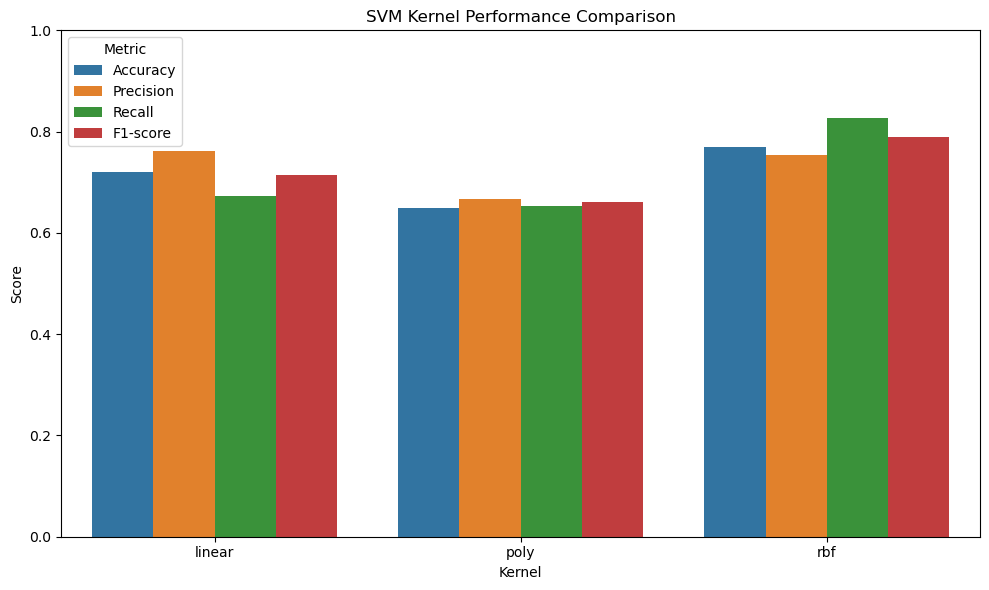

In [28]:

# STEP 17: Compare Kernel Performance Visually

results_melted = results_df.melt(
    id_vars="Kernel",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_melted,
    x="Kernel",
    y="Score",
    hue="Metric"
)

plt.title("SVM Kernel Performance Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


Step 18: Final conclusion

In [29]:

# STEP 18: Generate Conclusion from Actual Results

best_kernel_row = results_df.loc[
    results_df["F1-score"].idxmax()
]

print("CONCLUSION")
print("==========")

print(
    f"The best kernel among the three basic models is "
    f"{best_kernel_row['Kernel']}."
)

print(
    f"Its test accuracy is {best_kernel_row['Accuracy']:.4f} "
    f"and its F1-score is {best_kernel_row['F1-score']:.4f}."
)

print(
    f"The optimized model uses: {grid_search.best_params_}"
)

print(
    "SVM was used to classify drug response into "
    "0 (No Response) and 1 (Positive Response)."
)

print(
    "These results are for the supplied dataset and do not "
    "establish clinical effectiveness or support medical decisions."
)


CONCLUSION
The best kernel among the three basic models is rbf.
Its test accuracy is 0.7700 and its F1-score is 0.7890.
The optimized model uses: {'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'rbf'}
SVM was used to classify drug response into 0 (No Response) and 1 (Positive Response).
These results are for the supplied dataset and do not establish clinical effectiveness or support medical decisions.
